# Basic Classification

Our goal in this notebook is to get a handle on the basic task of classification. To do this, we'll use scikit-learn to create some simple synthetic datasets, we'll use these datasets to train some models, and we'll see how the models transform inputs to outputs.

The goal of machine learning is to automate prediction. We are surrounded by data, and as humans we make predictions based on this data all the time. Historically, people have been skittish about "predicting the future," but in a lot of cases it's really not that hard. If we see a lot of data and notice that it conforms to a pattern, we can use our knowledge of that pattern to make predictions similar data we see in the future. In a sense, all of machine learning is just a matter of formalizing that intuition and expressing it in a way that's easy to write code for. The problem we're going to look at should walk you through the basics of how that's done:

Let's start by importing what we need:

In [6]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn import datasets

To make our predictions about data, we're going to build a classifier. A _classifier_ is a function $c : \mathbb{R}^n \rightarrow X$. If you've never seen this notation before, it's just an easy way to say the following: "$c$ is a function. It takes inputs from the set $\mathbb{R}^n$ and produces values from the set $X$." In other words, that notation is just the concise way that mathematicians write down the _types_ of their functions.

The notation $\mathbb{R}^n$ is short for "vectors of length $n$, with components that are real numbers." So the input to a classifier is a vector of (for us) floating point numbers. Most of the basic machine learning algorithms assume that inputs appear in the form of floating-point vectors.

In the case of classification, the set $X$ is a finite set of _labels_. In the simplest case, called _two-class classification_, the set has two labels as elements. Depending on the application, these labels could be "spam" and "not spam", in which case $X = \\{"spam", "not spam"\\}$. Or the labels could be "happy" and "sad", in which case $X = \\{"happy", "sad"\\}$. Of course, it's much simpler if instead of strings for labels we just use numbers, so usually we just say $X = \\{0, 1\\}$, and then somewhere else write down the relationship between the numbers and the strings we really care about.

If we have a classifier $c$ available to us, we can use it to predict labels for inputs that we've never seen before (to a first approximation, this is what gmail is doing when it reads your incoming mail - using a spam classifier to decide whether or not to show you the incoming mail). In the real world, this is never what happens. Instead, if we're lucky, we get a bunch of data points with labels, and we need to _train_ a classifier using the available data and labels.

(In the real real world, things are even worse. Usually you don't even get labels. And a lot of the time you're just handed a file of stuff, and you have to clean and transform the data to get something you can use to train a classifier. For now, we'll ignore those details.)

The scikit-learn `datasets.make_classification` function gives this kind of data. Don't worry about what all the parameters below mean - just focus on the fact that `easy_x` is a $400 \times 2$ matrix and `easy_y` is a $400 \times 1$ column vector.

In [7]:
(easy_x, easy_y) = datasets.make_classification(n_samples=400, n_features = 2, n_informative = 2,
                             n_redundant = 0, n_repeated = 0, n_clusters_per_class=1, class_sep=1.5)

In [8]:
print(easy_x.shape)
print(easy_y.shape)

(400, 2)
(400,)


To understand what `easy_x` and `easy_y` are doing, we can look at the first few rows of each:

In [9]:
print(easy_x[0,:], easy_y[0])
print(easy_x[1,:], easy_y[1])

[-1.26710567  1.62055142] 0
[-2.27210842  0.10762217] 0


You can read these lines as saying "the point [..., ...] has the label ..." and "the point [..., ...] has the label ..." So each row of the matrix `easy_x` is a data point, and the corresponding element of `easy_y` is that data point's label. 

Looking at the data in this case is really easy (each row is small, there aren't many labels, and there aren't that many rows). But you can really see what's going on if you visualize the data. Exploratory visualization is almost always a good idea. Let's plot the points with different colors for each of the two labels:

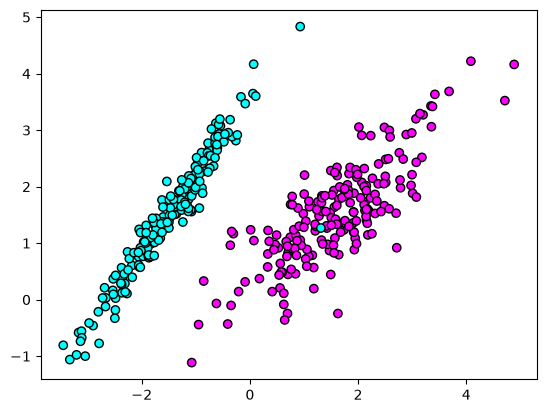

In [10]:
plt.scatter(easy_x[:,0], easy_x[:,1], c = easy_y, cmap = 'cool', edgecolor='black')

Points that are close together get similar or identical labels. You can implement this directly using the idea of "nearest neighbors," where you assign a label to a new point by looking at the $k$ nearest neighbors of the new point and let those neighbors "vote" on which label the point should get. Here's how that would work in scikit-learn:

In [11]:
from sklearn import neighbors

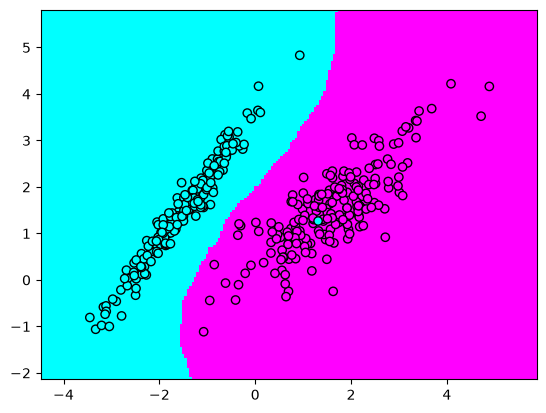

In [14]:
# these two lines create a classifier and train the classifier.
n_neighbors = 10
nn_classifier = neighbors.KNeighborsClassifier(n_neighbors=n_neighbors, weights='distance')
nn_classifier.fit(easy_x, easy_y)

# These seven lines show how points in a grid would be classified
h = 0.05 # mesh size
x_min, x_max = easy_x[:, 0].min() - 1, easy_x[:,0].max() + 1
y_min, y_max = easy_x[:, 1].min() - 1, easy_x[:,1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
Z = nn_classifier.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)
plt.figure()
plt.pcolormesh(xx,yy, Z, cmap='cool')

# this line plots the training data
plt.scatter(easy_x[:,0], easy_x[:,1], c=easy_y, cmap='cool', edgecolors='black')

Even though the classifier uses neighbor voting to decide how to classify points, in this case we can see that it has almost the same effect as drawing a line in the plane and using that line to perform classification. In a sense, this is how many machine learning systems operate. We can see this by looking at a slightly more sophisticated classifier, called _logistic regression_. 

Once we fit the classifier, we can see what labels it will assign to new inputs:

In [17]:
nn_classifier.predict([[2,-6]]) # note second pair of brackets

array([1])

## Logistic Regression

In [19]:
from sklearn.linear_model import LogisticRegression

lr_classifier = LogisticRegression()
lr_classifier.fit(easy_x, easy_y)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

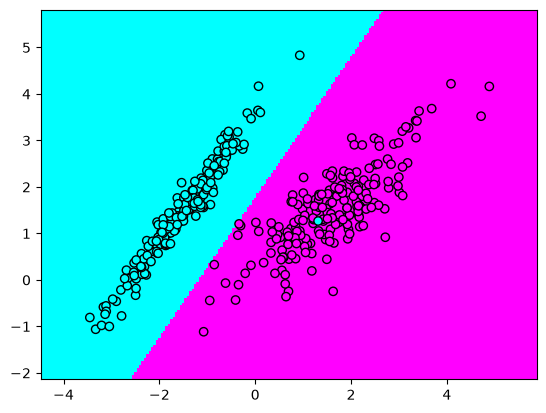

In [21]:
# just plotting...
Z_lr = lr_classifier.predict(np.c_[xx.ravel(), yy.ravel()])
Z_lr = Z_lr.reshape(xx.shape)
plt.figure()
plt.pcolormesh(xx,yy, Z_lr, cmap='cool')
plt.scatter(easy_x[:,0], easy_x[:,1], c=easy_y, cmap='cool', edgecolors='black')

## Responsible Evaluation

Once we have a classifier, we can run it as we did above to see how it performs on some data. But the approach that we used above has a serious problem - we have no way of knowing how well the classifier will perform if we use it in the field. How would you pick between the kNN classifier and logistic regression above? If the classes are easily separable it doesn't matter, but in the real world we can't just glance at the geometry to see how well the classes can be separated. We need something more quantitative, that will generalize to higher dimensions than two or three.

The first thing you might try is only training on a fraction of the given data, using the rest for evaluation purposes. This approach, which is standard in the ML community, uses a _training set_ and a _test set_. Let's see how that works by generating a new data set:

In [22]:
(new_x, new_y) = datasets.make_classification(n_samples=600, n_features = 2, n_informative = 2,
                             n_redundant = 0, n_repeated = 0, n_clusters_per_class=1, class_sep=1.0)

To break this new data into training and test, let's just take the first 500 points for training and the last 100 for test:

In [23]:
training_x, training_y = new_x[:500, :], new_y[:500]
test_x, test_y = new_x[-100:, :], new_y[-100:]

Let's use the `score` function to see how well the classifier performs on the test data. Numbers close to 0 are bad and numbers close to 1 are good: 

In [24]:
lr2_clf = LogisticRegression()
lr2_clf.fit(training_x, training_y).score(test_x, test_y)

0.96

Lastly, we can generalize this training/test split to multiple folds using `cross_val_score`:

In [26]:
from sklearn.model_selection import KFold, cross_val_score

kfold = KFold(n_splits=3)

scores = cross_val_score(
    lr2_clf, test_x, test_y,
    cv=kfold,
    n_jobs=-1,
)
scores

array([1.        , 0.87878788, 0.93939394])